AF 8-2025

# Just boys, just video games

Now that there's an actual angle, broken out by demographics

In [47]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

source = "..//data//source//"
processed = "..//data//processed//"

long_glob = glob.glob(processed + "0324//atus*.csv")
print(long_glob)

a = {}

for path in long_glob: 

    name = path.split("/")[-1][4:-9]

    a[name] = pd.read_csv(path)

['..//data//processed//0324/atussum-0324.csv', '..//data//processed//0324/atusresp-0324.csv', '..//data//processed//0324/atusact-0324.csv', '..//data//processed//0324/atuscps-0324.csv', '..//data//processed//0324/atusrost-0324.csv', '..//data//processed//0324/atuswho-0324.csv']


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_46542/3828175635.py:23: DtypeWarning: Columns (25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  a[name] = pd.read_csv(path)


In [9]:
# filter out the 1) boys 2) under 35 3) 2004 and after

sum_variables = ["TUCASEID", # ID
                 "TUYEAR", # Year
                "TESCHENR", # School enrollment
                "TRSPPRES", # Presence of spouse
                "TUDIARYDAY", # day of week
                "TESEX", # Sex
                "TRERNWA", # Weekly earnings 
                "TEHRUSLT", # Usual weekly hours of work 
                "TESCHLVL", # school level
                "TUFNWGTP", # Weight
                "TEAGE", # Age 
                "PTDTRACE", # Race
                "PEHSPNON", # Hispanic Origin
                "PEEDUCA", # Educational attainment
                "GTMETSTA", # new metro status
                "GEMETSTA", # old metro status
                "TELFS", # employment status
                "age_bin_10" # age bucket category
]

a['sum']['year'] = a['sum']['TUCASEID'].astype(str).str[:4].astype(int)

a['sum']['age_bin_10'] = pd.cut(a['sum']['TEAGE'], bins = [15, 25, 35, 45, 55, 65, 75, 85, np.inf], right =False)

a['sum'].head()

sample = a['sum'][(a['sum']['year']>=2004)]
sample = sample[sum_variables]

SAMPLE_IDS = sample.TUCASEID

In [10]:
# now let's filter for all the video games

games = a['act'][a['act'].TUCASEID.isin(SAMPLE_IDS) & (a['act']['TRCODEP'] == 120307)]
games.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP
412880,20040101040590,7,60,0,0,0,-1,0,14:25:00,15:25:00,120307,12,1203,0,685,685,60,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,-1
412888,20040101040590,15,90,0,0,0,-1,0,21:00:00,22:30:00,120307,12,1203,0,1110,1110,90,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,-1
412935,20040101040600,25,105,0,0,0,-1,0,18:15:00,20:00:00,120307,12,1203,0,960,960,105,-1,-1,-1,-1,-1,-1,3,0,-1,-1,-1,-1
413278,20040101040774,7,180,0,0,0,-1,0,13:00:00,16:00:00,120307,12,1203,0,720,720,180,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,-1
413283,20040101040774,12,150,0,0,0,-1,0,16:30:00,19:00:00,120307,12,1203,0,900,900,150,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,-1


## by age group

In [28]:
g = games.groupby('TUCASEID')['TUACTDUR24'].sum().reset_index()

In [41]:

sumgames = pd.merge(a['sum'][sum_variables], g, on = 'TUCASEID', how = 'left', validate = '1:m')
sumgames['TUACTDUR24'] = sumgames['TUACTDUR24'].replace(np.nan, 0)
sumgames.head()


,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,TELFS,age_bin_10,TUACTDUR24
0,20030100013280,2003,-1,1,6,1,66000,30,-1,8.155463e+06,60,2,2,44,-1,1,2,"[55.0, 65.0)",0.0
1,20030100013344,2003,2,1,7,2,20000,30,-1,1.735323e+06,41,1,2,40,-1,2,1,"[35.0, 45.0)",0.0
2,20030100013352,2003,2,1,7,2,20000,12,-1,3.830527e+06,26,1,2,41,-1,1,2,"[25.0, 35.0)",0.0
3,20030100013848,2003,2,1,5,2,-1,-1,-1,6.622023e+06,36,2,2,39,-1,2,4,"[35.0, 45.0)",0.0
4,20030100014165,2003,-1,1,5,1,-1,80,-1,3.068387e+06,51,1,2,45,-1,2,1,"[45.0, 55.0)",0.0


In [45]:
# i need the weighted average by year 

final = sumgames.groupby(['TUYEAR', 'TESEX', 'age_bin_10']).apply(lambda x: np.average(x.TUACTDUR24, weights = x.TUFNWGTP)) *7/60
final = final.reset_index()
to_plot = final.pivot_table(columns = 'TUYEAR', index = ['age_bin_10', 'TESEX'], values = 0, aggfunc= 'mean')

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_46542/1019343459.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  final = sumgames.groupby(['TUYEAR', 'TESEX', 'age_bin_10']).apply(lambda x: np.average(x.TUACTDUR24, weights = x.TUFNWGTP)) *7/60
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_46542/1019343459.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  final = sumgames.groupby(['TUYEAR', 'TESEX', 'age_bin_10']).apply(lambda x: np.average(x.TUACTDUR24, weights = x.TUFNWGTP)) *7/

In [51]:
to_plot

TUYEAR              2003      2004      2005      2006      2007      2008  \
age_bin_10   TESEX                                                           
[15.0, 25.0) 1       0.0  4.588154  3.903465  4.044849  4.399646  4.638871   
             2       0.0  1.079088  1.113276  0.919351  0.993010  1.098834   
[25.0, 35.0) 1       0.0  1.683965  1.941637  2.125225  1.448341  1.963506   
             2       0.0  0.461315  0.662323  0.569121  1.031635  0.697641   
[35.0, 45.0) 1       0.0  0.640351  0.777528  0.999138  1.369743  0.941157   
             2       0.0  0.622531  0.738491  0.443549  0.517773  0.685424   
[45.0, 55.0) 1       0.0  0.385137  0.474965  0.833284  0.435504  0.438764   
             2       0.0  0.543975  0.421341  0.605435  0.566997  0.789157   
[55.0, 65.0) 1       0.0  0.758365  0.509925  0.670780  0.952114  0.563990   
             2       0.0  0.987621  1.401454  0.952753  0.719758  1.219835   
[65.0, 75.0) 1       0.0  0.787030  1.423548  0.975644  1.188621  1.318636   
             2       0.0  1.592614  1.737962  1.271596  2.234417  1.885077   
[75.0, 85.0) 1       0.0  1.628609  1.214522  1.108218  1.271733  1.649136   
             2       0.0  2.188035  2.255832  2.015655  1.942170  1.974440   
[85.0, inf)  1       NaN       NaN  2.627446  2.019306  1.225585  2.388590   
             2       NaN       NaN  0.932100  3.849808  1.326730  3.098021   

TUYEAR                  2009      2010      2011      2012      2013  \
age_bin_10   TESEX                                                     
[15.0, 25.0) 1      4.496365  5.699939  6.735967  5.697618  6.324145   
             2      1.551188  1.429492  1.256406  1.128745  0.766966   
[25.0, 35.0) 1      2.274626  1.848456  2.023605  2.383886  2.672086   
             2      0.879588  0.490554  0.796419  0.821352  0.493748   
[35.0, 45.0) 1      1.272778  1.001994  0.927462  0.861224  1.084907   
             2      0.697891  0.693833  0.314845  0.700871  0.542683   
[45.0, 55.0) 1      0.547234  0.541498  0.453186  0.487893  0.455338   
             2      1.278445  0.584533  0.802805  0.825643  0.662532   
[55.0, 65.0) 1      0.561774  0.947204  0.427090  0.495365  0.777884   
             2      1.497302  1.113697  1.296628  0.837185  1.134269   
[65.0, 75.0) 1      1.325653  0.587509  0.496775  1.039590  1.393803   
             2      1.676133  1.740356  1.717919  1.480733  1.957186   
[75.0, 85.0) 1      1.776082  1.702964  0.718893  1.093832  2.050304   
             2      1.966169  2.778100  2.233028  2.043197  1.604582   
[85.0, inf)  1      1.587043  0.461362  0.343140  1.550067  3.436361   
             2      2.860122  1.594459  2.746295  2.799277  1.961424   

TUYEAR                  2014      2015      2016      2017      2018  \
age_bin_10   TESEX                                                     
[15.0, 25.0) 1      6.193083  6.635218  6.139339  7.791133  8.236603   
             2      0.834154  1.377117  1.712574  3.366548  1.922792   
[25.0, 35.0) 1      2.345204  2.345884  2.584008  3.078970  4.078264   
             2      0.832357  0.572587  1.319672  0.844198  0.981387   
[35.0, 45.0) 1      0.612344  0.811486  1.333901  0.732947  1.369998   
             2      0.636570  0.631108  0.475486  0.529825  0.828301   
[45.0, 55.0) 1      0.642762  0.776910  0.633357  0.756440  0.744405   
             2      0.765267  0.721919  0.666831  0.928264  0.686580   
[55.0, 65.0) 1      0.775231  0.549531  0.473996  0.512763  0.700484   
             2      1.347634  0.922057  1.109429  1.056521  1.259563   
[65.0, 75.0) 1      0.903459  1.150728  0.803283  1.011213  0.854025   
             2      1.840577  2.033960  1.906178  2.022326  1.631583   
[75.0, 85.0) 1      1.407939  2.194583  1.440781  0.636597  1.194876   
             2      2.400801  2.182665  3.261859  2.031340  2.685151   
[85.0, inf)  1      0.830250  2.461962  1.037925  0.848804  1.339541   
             2      4.026007  2.794287  2.471799  4.568121  1.706251   

T

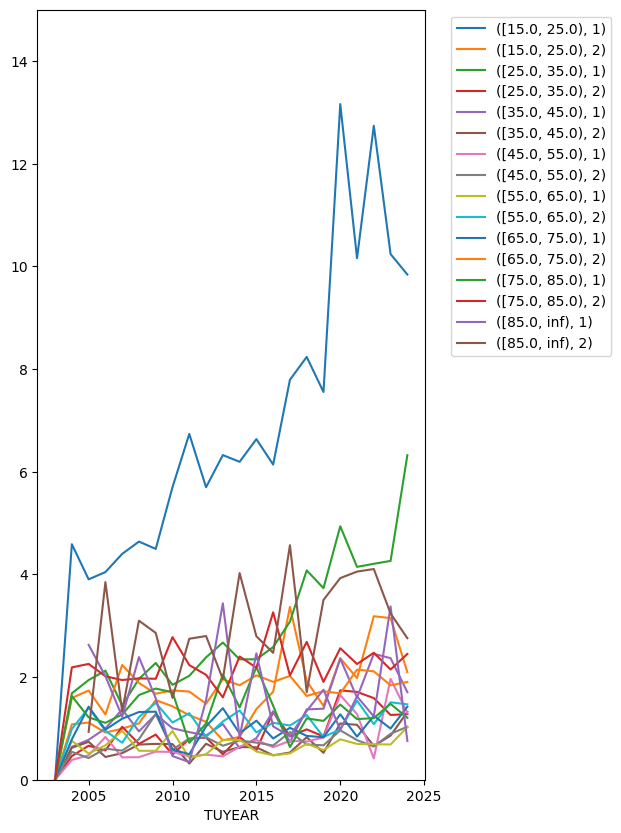

In [50]:
to_plot.T.plot(ylim = (0,15), figsize=(5, 10))
plt.legend(bbox_to_anchor = (1.05, 1), loc = 'upper left')

## back to regularly scheduled programming

In [7]:
sample.head()

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,TELFS
20720,20040101040003,2004,-1,3,7,1,-1,-1,-1,3.158614e+06,71,2,2,39,-1,1,5
20721,20040101040060,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,5
20722,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1,1
20723,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1,1
20724,20040101040110,2004,2,3,2,1,26000,40,-1,9.062125e+06,42,1,2,36,-1,1,1


In [5]:
# now let's figure out the activities done alone 
print(a['who'].shape)
who = a['who'].drop_duplicates(['TUCASEID', 'TUACTIVITY_N'], keep=False)
who = pd.merge(who, games[['TUCASEID', 'TUACTIVITY_N']], on = ['TUCASEID', 'TUACTIVITY_N'], how = 'inner')  # who[who.TUCASEID.isin(games.TUCASEID)]
print(who.shape)

who_alone = who[((who.TUWHO_CODE==18)| (who.TUWHO_CODE==19))].drop(['TULINENO', 'TRWHONA', 'TUWHO_CODE'], axis =1)
who_alone = who_alone[who_alone.TUCASEID.isin(SAMPLE_IDS)]
who_alone['alone'] = 1
print(who_alone.shape)

who_alone.head()

(6221596, 5)
(6946, 5)
(4400, 3)


,TUCASEID,TUACTIVITY_N,alone
2,20040101041582,5,1
11,20040111032672,16,1
13,20040111032672,39,1
15,20040111032937,13,1
16,20040111033424,4,1


In [6]:
games.shape

(7994, 29)

In [7]:
act_who = pd.merge(games, who_alone, on = ['TUCASEID', 'TUACTIVITY_N'], how = 'outer', validate = '1:1')
act_who.alone = act_who.alone.fillna(0)
act_who.tail(20)

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP,alone
7974,20241210241146,10,120,0,0,0,-1,0,02:00:00,05:00:00,120307,12,1203,0,1500,1440,180,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,2,1.0
7975,20241210241181,28,120,0,0,0,-1,0,19:00:00,21:00:00,120307,12,1203,0,1020,1020,120,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0
7976,20241210241401,11,60,1,0,60,60,0,20:00:00,21:00:00,120307,12,1203,0,1020,1020,60,-1,60,-1,60,60,-1,3,0,-1,-1,-1,1,0.0
7977,20241210241859,4,90,1,0,90,90,0,08:04:00,09:34:00,120307,12,1203,0,334,334,90,-1,90,-1,90,90,-1,1,0,-1,-1,-1,1,0.0
7978,20241210242076,10,60,1,0,5,5,0,20:25:00,21:25:00,120307,12,1203,0,1045,1045,60,-1,5,-1,5,5,-1,1,0,-1,-1,-1,1,0.0
7979,20241211240187,16,120,0,0,0,-1,0,18:00:00,20:00:00,120307,12,1203,0,960,960,120,-1,-1,-1,-1,-1,-1,3,0,-1,-1,-1,1,0.0
7980,20241211240269,4,130,0,0,0,-1,0,09:20:00,11:30:00,120307,12,1203,0,450,450,130,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,2,1.0
7981,20241211240299,15,210,0,0,0,-1,0,21:30:00,01:00:00,120307,12,1203,0,1260,1260,210,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,2,1.0
7982,20241211240306,11,120,0,0,0,-1,0,15:55:00,17:55:00,120307,12,1203,0,835,835,120,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0
7983,20241211240306,17,120,0,0,0,-1,0,19:50:00,21:50:00,120307,12,1203,0,1070,1070,120,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0


In [8]:
act_who_agg = act_who.pivot_table(index = 'TUCASEID', columns= 'alone', values = 'TUACTDUR24', aggfunc=sum)
act_who_agg.columns = ['with_others', 'alone']
act_who_agg = act_who_agg.fillna(0).reset_index()
act_who_agg['total'] = act_who_agg['alone'] + act_who_agg['with_others']
act_who_agg.head()

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_32371/563217774.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  act_who_agg = act_who.pivot_table(index = 'TUCASEID', columns= 'alone', values = 'TUACTDUR24', aggfunc=sum)


,TUCASEID,with_others,alone,total
0,20040101040774,330.0,0.0,330.0
1,20040101041582,0.0,240.0,240.0
2,20040101042120,100.0,0.0,100.0
3,20040101042150,120.0,0.0,120.0
4,20040101042269,60.0,0.0,60.0


In [9]:
final = pd.merge(sample, act_who_agg, on = 'TUCASEID', how = 'left', validate = "1:1", indicator = 'games')
print(final.games.value_counts())
final[['alone', 'with_others', 'total']] = final[['alone', 'with_others', 'total']].fillna(0)
final.head()

games
left_only     20832
both           5513
right_only        0
Name: count, dtype: int64


,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,TELFS,with_others,alone,total,games
0,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1,1,0.0,0.0,0.0,left_only
1,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1,1,0.0,0.0,0.0,left_only
2,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,1,0.0,0.0,0.0,left_only
3,20040101040604,2004,2,1,7,1,-1,-1,-1,2.806461e+06,32,1,2,42,-1,1,5,0.0,0.0,0.0,left_only
4,20040101040617,2004,2,3,7,1,63461,40,-1,6.381670e+06,32,2,2,43,-1,1,1,0.0,0.0,0.0,left_only


In [10]:
# i need the weighted average by year 

final.groupby(['TUYEAR', 'PTDTRACE']).apply(lambda x: np.average(x.total, weights = x.TUFNWGTP)) *7/60

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_32371/1540612333.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  final.groupby(['TUYEAR', 'PTDTRACE']).apply(lambda x: np.average(x.total, weights = x.TUFNWGTP)) *7/60


TUYEAR  PTDTRACE
2004    1            3.344494
        2            2.592866
        3            1.925630
        4            1.673391
        5            0.000000
        6            6.705691
        7            4.566991
        8            0.000000
        9            0.000000
        11           0.000000
        12           0.000000
        14           0.000000
        15           0.000000
2005    1            2.830383
        2            3.707142
        3            0.289726
        4            4.001512
        5            8.767378
        6            0.000000
        7            1.673119
        8            2.439531
        9            0.000000
        11          27.066667
        13           0.000000
        15           0.000000
        21           0.000000
2006    1            2.817957
        2            5.579510
        3            0.000000
        4            3.136401
        5            0.000000
        6            1.026987
        7            1.

<Axes: title={'center': 'by race (1 = white, 2 = black , 4 = asian)'}, xlabel='TUYEAR'>

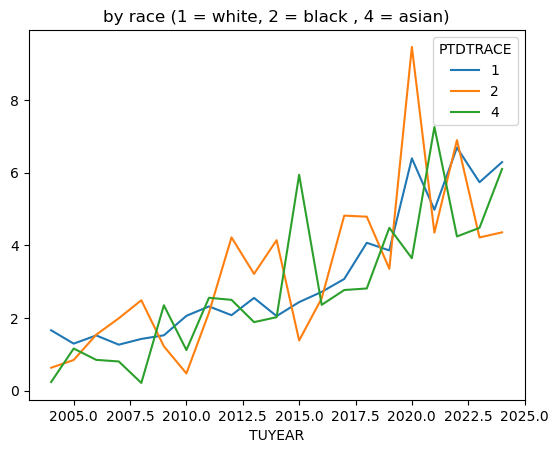

In [28]:
by_race = final.pivot_table(index = 'TUYEAR', columns = 'PTDTRACE', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) *7/60
by_race[[1,2,4]].plot(title = 'by race (1 = white, 2 = black , 4 = asian)')

<Axes: title={'center': 'by ethnicity (1 = hispanic/latino, 2 = not hispanic/latino)'}, xlabel='TUYEAR'>

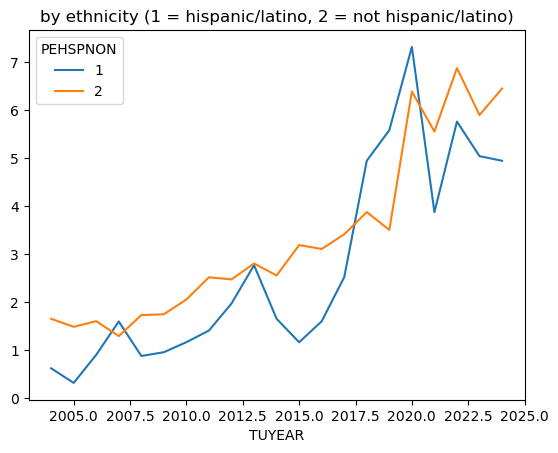

In [29]:
# ethnicity
by_ethnicity = final.pivot_table(index = 'TUYEAR', columns = 'PEHSPNON', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) * 7 /60
by_ethnicity.plot(title = 'by ethnicity (1 = hispanic/latino, 2 = not hispanic/latino)')


<Axes: title={'center': "by education level (39 = high school diploma,\n40 = some college but no degree, 43 = bachelor's degree)"}, xlabel='TUYEAR'>

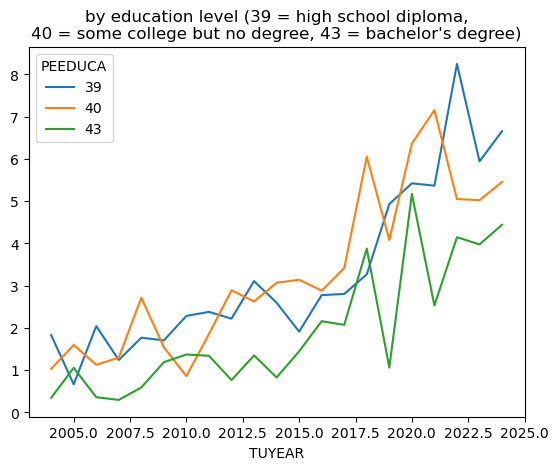

In [31]:
# education
by_education = final.pivot_table(index = 'TUYEAR', columns = 'PEEDUCA', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) * 7 /60
by_education[[39, 40, 43]].plot(title = "by education level (39 = high school diploma,\n40 = some college but no degree, 43 = bachelor's degree)")


In [14]:
by_education.tail()

PEEDUCA,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46
TUYEAR,,,,,,,,,,,,,,,,
2020,-0.0,-0.0,-0.000000,15.680000,14.799510,12.155085,12.571345,9.683333,5.423250,6.362403,2.196078,5.068217,5.170268,1.481667,7.048611,-0.000000
2021,NaN,NaN,0.342213,0.640545,9.330568,8.718427,5.975059,4.523977,5.367322,7.155864,2.435999,3.603439,2.531492,3.454653,2.081862,0.257145
2022,0.0,0.0,0.000000,4.779790,10.073807,10.950505,14.833606,4.844755,8.249134,5.051851,1.125419,0.453865,4.147481,1.414772,7.144688,0.000000
2023,NaN,0.0,1.902426,6.506560,12.568985,13.144418,9.430611,2.576690,5.942224,5.023436,0.690417,2.356186,3.977822,0.871561,0.000000,1.131759
2024,NaN,0.0,0.000000,0.000000,9.269628,5.814681,9.988318,4.056241,6.657783,5.455877,6.198357,7.732997,4.441756,5.543890,5.954220,0.421175


In [15]:
by_education_count = final.pivot_table(index = 'TUYEAR', columns = 'PEEDUCA', values = 'alone', aggfunc = 'count') 
by_education_count

PEEDUCA,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46
TUYEAR,,,,,,,,,,,,,,,,
2004,1.0,16.0,20.0,72.0,169.0,146.0,130.0,33.0,395.0,295.0,55.0,43.0,277.0,56.0,20.0,15.0
2005,2.0,7.0,32.0,65.0,147.0,136.0,120.0,21.0,360.0,286.0,64.0,50.0,248.0,49.0,10.0,10.0
2006,1.0,1.0,23.0,73.0,148.0,151.0,127.0,25.0,362.0,260.0,57.0,39.0,235.0,62.0,12.0,9.0
2007,3.0,4.0,25.0,57.0,133.0,134.0,117.0,23.0,330.0,258.0,65.0,51.0,226.0,63.0,9.0,5.0
2008,NaN,4.0,21.0,64.0,129.0,134.0,120.0,30.0,343.0,271.0,53.0,62.0,236.0,67.0,13.0,18.0
2009,1.0,2.0,15.0,52.0,120.0,132.0,120.0,23.0,349.0,279.0,49.0,64.0,261.0,58.0,14.0,8.0
2010,2.0,3.0,16.0,50.0,112.0,139.0,128.0,33.0,374.0,290.0,45.0,52.0,266.0,59.0,14.0,14.0
2011,2.0,8.0,17.0,46.0,102.0,106.0,110.0,27.0,307.0,280.0,42.0,49.0,233.0,66.0,16.0,14.0
2012,1.0,2.0,17.0,43.0,99.0,120.0,100.0,20.0,297.0,296.0,48.0,49.0,266.0,74.0,27.0,8.0


<Axes: title={'center': 'by metro status (1 = metropolitan, 2 = non-metropolitan)'}, xlabel='TUYEAR'>

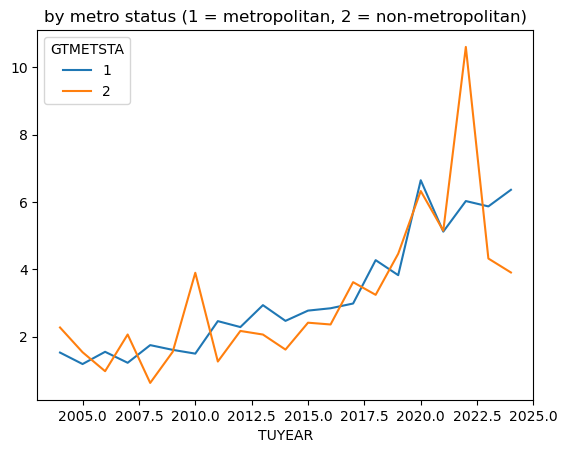

In [34]:
# metropolitan status
by_metro_status = final.pivot_table(index = 'TUYEAR', columns = 'GTMETSTA', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) * 7 /60
by_metro_status[[1,2]].plot(title = "by metro status (1 = metropolitan, 2 = non-metropolitan)")

In [35]:
final['TRERNWA'].describe()

count    2.634500e+04
mean     5.810396e+04
std      6.644073e+04
min     -1.000000e+00
25%     -1.000000e+00
50%      4.133000e+04
75%      9.000000e+04
max      1.077283e+06
Name: TRERNWA, dtype: float64

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_32371/2941229601.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  inc['inc_q'] = inc.groupby('TUYEAR')['TRERNWA'].transform(lambda x: pd.qcut(x, 4, labels = range(1,5)) )
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_32371/2941229601.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  by_inc= inc.pivot_table(index = 'TUYEAR', columns = 'inc_q', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) * 7 /60


<Axes: title={'center': 'by income quartile (individual earnings not household,\nonly includes those with reported earnings)'}, xlabel='TUYEAR'>

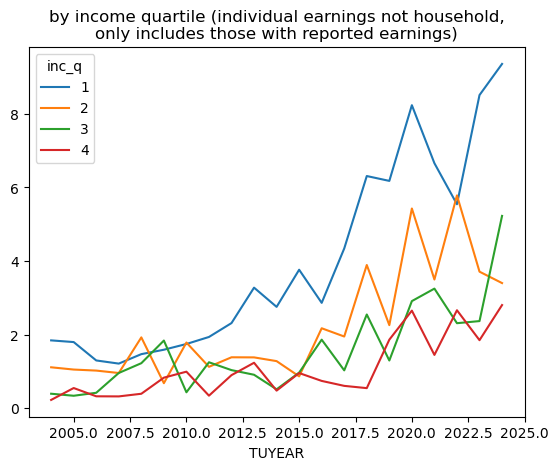

In [41]:
# for income, could do income quartiles by year? 
# we will probably only look at the 

inc = final[final.TRERNWA>-1]
inc['inc_q'] = inc.groupby('TUYEAR')['TRERNWA'].transform(lambda x: pd.qcut(x, 4, labels = range(1,5)) )

by_inc= inc.pivot_table(index = 'TUYEAR', columns = 'inc_q', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) * 7 /60
by_inc.plot(title = 'by income quartile (individual earnings not household,\nonly includes those with reported earnings)')

<Axes: title={'center': 'by employment status (1 = employed - at work,\n4 = unemployed - looking, 5 = not in labor force)'}, xlabel='TUYEAR'>

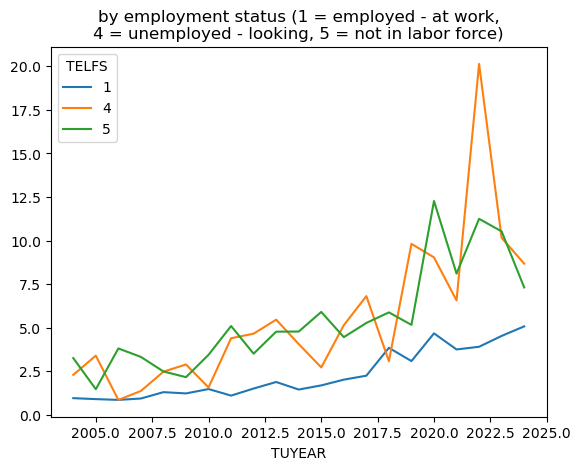

In [38]:
# by employment status 

by_employment_status = final.pivot_table(index = 'TUYEAR', columns = 'TELFS', values = 'alone', aggfunc = lambda x: np.average(x, weights = final.loc[x.index, 'TUFNWGTP'])) * 7 /60
by_employment_status[[1,4,5]].plot(title = 'by employment status (1 = employed - at work,\n4 = unemployed - looking, 5 = not in labor force)')

In [21]:
final.pivot_table(index='TUYEAR', columns='TELFS', values = 'alone', aggfunc='count').T

TUYEAR,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
TELFS,,,,,,,,,,,,,,,,,,,,,
1,1263,1187,1131,1120,1139,1067,1054,970,975,916,937,833,822,794,727,773,644,694,643,641,607
2,36,37,33,29,44,27,41,27,25,22,28,32,29,26,24,22,31,38,21,24,24
3,11,16,13,8,10,23,12,13,9,8,10,7,5,3,1,6,10,6,5,4,1
4,135,120,109,97,124,179,193,150,145,112,107,78,73,70,45,54,61,47,33,37,42
5,298,247,299,249,248,251,297,265,313,255,242,224,218,179,182,154,196,165,120,86,108


In [27]:
final.sort_values('alone', ascending=False).head(20)

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,TELFS,with_others,alone,total,games
5721,20070705070913,2007,1,3,7,1,-1,-1,2,1.114473e+07,20,1,1,37,1,-1,5,0.0,1156.0,1156.0,both
14496,20130403131858,2013,2,3,1,1,150000,60,-1,3.191215e+06,28,2,2,39,1,-1,1,0.0,1020.0,1020.0,both
12146,20110808110152,2011,1,3,1,1,-1,-1,1,6.359403e+06,16,1,2,36,2,-1,4,0.0,1018.0,1018.0,both
13759,20121009121695,2012,2,3,7,1,-1,-1,-1,3.999361e+06,19,1,2,39,1,-1,4,0.0,1010.0,1010.0,both
22327,20200504200395,2020,1,3,7,1,-1,-1,1,-1.000000e+00,16,2,2,35,1,-1,5,0.0,960.0,960.0,both
21755,20190907192148,2019,2,3,1,1,-1,-1,-1,8.296395e+06,30,2,2,39,2,-1,5,0.0,950.0,950.0,both
22092,20200112190182,2020,1,3,6,1,-1,-1,1,-1.000000e+00,16,1,1,37,1,-1,5,0.0,940.0,940.0,both
9561,20100101101829,2010,1,3,7,1,-1,-1,1,4.672289e+06,17,1,1,37,1,-1,5,0.0,905.0,905.0,both
21737,20190807192255,2019,2,3,7,1,34615,40,-1,1.115960e+07,34,1,2,39,1,-1,1,0.0,875.0,875.0,both
22233,20200302200177,2020,1,3,1,1,-1,-1,1,-1.000000e+00,17,1,1,36,2,-1,5,0.0,874.0,874.0,both
